# OSTIA versus OISST off Peru: product and resolution effects

The same marine heatwave analysis runs in three arms on one 32 x 20 box (12°S–4°S, 82°W–77°W, 1991–2025): NOAA OISST at 0.25°, Met Office OSTIA averaged to the same 0.25° cells, and OSTIA at its native 0.05°. Comparing OISST with OSTIA 0.25° measures the **product effect**; comparing OSTIA 0.25° with OSTIA 0.05° measures the **resolution effect**. Every arm uses the same definition, the same fixed 1991–2020 climatology and the same spatial recipe. The OISST arm reproduces the registered case (16,702 events, 118 tracks). Reproduced numbers are pending scientific review.

Read [the tutorial guide](../docs/TUTORIALS.md#ostia-versus-oisst) for inputs and results. Saved outputs can be read without data; re-execution needs the compressed datasets of [the README](../README.md) and about 4 GB of memory (the native arm takes most of the 9 minutes). No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.1.0 |
| Source | xhw-test-datasets: oisst and ostia (content hashes in report.json) |
| Reference period | 1991-01-01 through 2020-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | surface / lat, lon |
| Domain / measure | ocean / area |
| Review status | executed; temporal and spatial summaries pending scientific review |

The three arms share these specifications; only the data and their grid differ. The spatial recipe (face patches of at least 5% of the ocean area, any shared-cell overlap, five-day tracks) is in its own cell. Full portable specs and checksums are in `report.json` and [the saved run record](../products/ostia_resolution/report.json).

In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "ostia"
# Optional bounded working arrays; see docs/REPRODUCIBILITY.md.
# Set XHW_MAPPED_ARRAYS=1 before starting this kernel on memory-limited machines.

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
import time

import numpy as np
import xarray as xr
from _data import load_resolution_study
from _report import frequency, spatial_summary, temporal_summary, write_report
from content_hash import content_sha256
from ostia_peru import (
    LABELS,
    SPATIAL,
    aggregate_fine_frequency,
    agreement,
    analyse,
    resolution_events_figure,
    resolution_frequency_figure,
    temperature_agreement,
)

import xhw

print(f"Publication API: xHW {xhw.__version__}")

## Open the compressed test datasets (their content hash is verified) and build the arms

The two compressed datasets are verified by their stored content before use. OSTIA is decoded from its integers to exact hundredths of a degree, both are matched by calendar day, and OSTIA is averaged over the 5 x 5 sub-cells of each OISST cell (an ocean cell needs at least 13 of 25).

In [4]:
datasets, paths = load_resolution_study(data_dir)
shas = {"oisst": content_sha256(paths["oisst"]), "ostia": content_sha256(paths["ostia"])}
print("Arms:", {k: dict(v.sizes) for k, v in datasets.items()})

Arms: {'oisst': {'lat': 32, 'lon': 20, 'time': 12784}, 'ostia_coarse': {'time': 12784, 'lat': 32, 'lon': 20}, 'ostia_fine': {'time': 12784, 'lat': 160, 'lon': 100}}


## Same specs, same recipe: detect and follow events in each arm

`analyse` runs fit, detect, catalog, objects, tracking and lineage for one arm, with every invariant check, so each arm has identical treatment.

In [5]:
resolutions = {
    "oisst": "0.25 degree",
    "ostia_coarse": "0.25 degree (mean of 5 x 5)",
    "ostia_fine": "0.05 degree",
}
arms = {}
for name, ds in datasets.items():
    start = time.perf_counter()
    arms[name] = analyse(name, ds, resolutions[name], shas["oisst" if name == "oisst" else "ostia"],
                          output_dir=output_dir)
    events = arms[name]["catalog"].dataset.sizes["event"]
    print(f"{name}: {events} per-cell events ({time.perf_counter() - start:.0f} s)", flush=True)

oisst: 16702 per-cell events (17 s)


ostia_coarse: 14536 per-cell events (15 s)


ostia_peru.py:96: XHWDataQualityWarning: min_area (domain_fraction 5) discards 28677 of 31343 patches (91 %): the cut (1.3116e+10 m2) may not suit the size of this domain; check `MinArea` (a percentile or a smaller fraction scales better to large domains)
  objects = xhw.build_objects(mask, recipe=SPATIAL, analysis_mode="retrospective")


ostia_fine: 371109 per-cell events (603 s)


## Compare: temperature, product effect and resolution effect

Temperature agreement, event agreement (product effect) and pooled-frequency agreement (resolution effect) on the cells that all arms share.

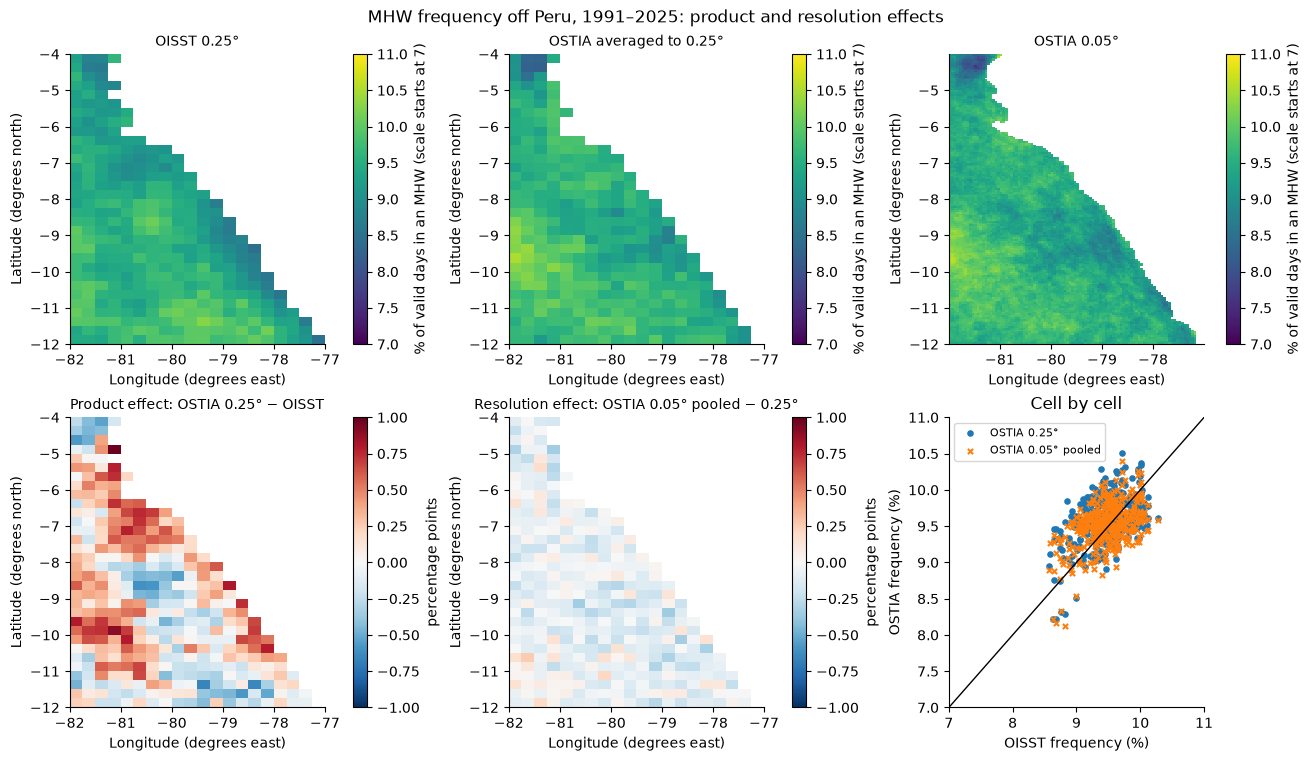

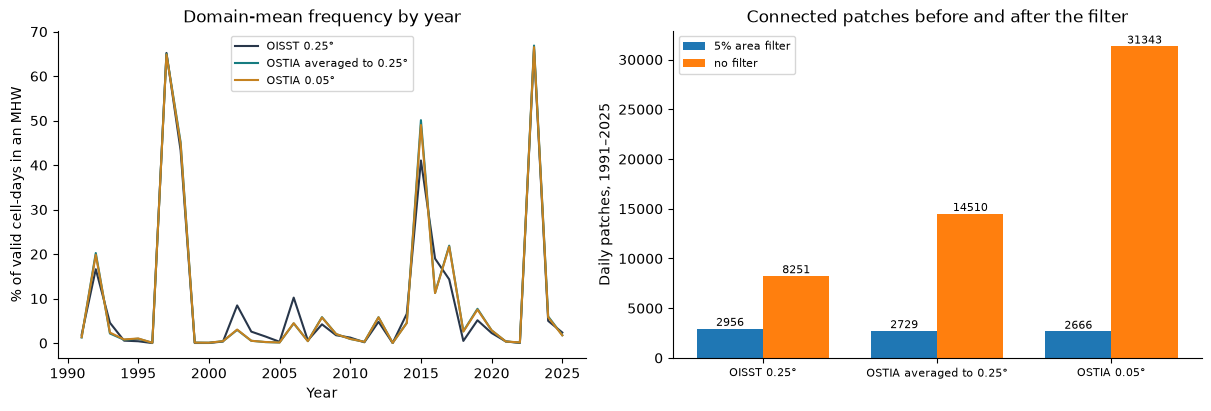

In [6]:
pooled = aggregate_fine_frequency(arms["ostia_fine"]["mask"], frequency(arms["oisst"]["mask"]))
base = frequency(arms["ostia_coarse"]["mask"])
both = base.notnull() & pooled.notnull()
metrics = {
    "arms": {
        name: {
            "ocean_cells": int(datasets[name]["domain_mask"].sum()),
            "temporal": temporal_summary(arm["mask"], arm["catalog"]),
            "spatial": spatial_summary(arm["objects"], arm["graph"]),
            "daily_patches_without_area_filter": arm["loose_count"],
            "event_cell_days_pct_of_valid": 100
            * float(arm["mask"].dataset["event_membership"].sum())
            / float(arm["mask"].dataset["valid"].sum()),
            "events_per_ocean_cell": arm["catalog"].dataset.sizes["event"]
            / int(datasets[name]["domain_mask"].sum()),
        }
        for name, arm in arms.items()
    },
    "temperature_oisst_vs_ostia_025": temperature_agreement(
        datasets["oisst"], datasets["ostia_coarse"]
    ),
    "product_effect_oisst_vs_ostia_025": agreement(
        arms["oisst"]["mask"], arms["ostia_coarse"]["mask"]
    ),
    "resolution_effect_ostia_025_vs_005_pooled": {
        "cells": int(both.sum()),
        "frequency_correlation": float(xr.corr(base.where(both), pooled.where(both))),
        "frequency_mean_difference_pct_points": float((pooled - base).where(both).mean()),
        "frequency_rmse_pct_points": float(np.sqrt(((pooled - base) ** 2).where(both).mean())),
    },
}
yearly = {
    name: (arm["mask"].dataset["event_membership"] & arm["mask"].dataset["valid"])
    .groupby("time.year")
    .sum(["time", "lat", "lon"])
    / arm["mask"].dataset["valid"].groupby("time.year").sum(["time", "lat", "lon"])
    for name, arm in arms.items()
}
metrics["yearly_domain_frequency_correlation"] = {
    "oisst_vs_ostia_025": float(xr.corr(yearly["oisst"], yearly["ostia_coarse"])),
    "ostia_025_vs_005": float(xr.corr(yearly["ostia_coarse"], yearly["ostia_fine"])),
}
figure = resolution_frequency_figure(arms, pooled, output_dir)
figure = resolution_events_figure(arms, output_dir)
del figure

## Record the run; the review state stays explicit

The report holds versions, exact specs, source checksum and review state.

In [7]:
fine = arms["ostia_fine"]
report = write_report(
    output_dir,
    "ostia",
    metrics,
    grid=fine["grid"],
    baseline=fine["baseline"],
    definition=fine["definition"],
    recipe=SPATIAL,
    graph=fine["graph"],
    review="executed; temporal and spatial summaries pending scientific review",
    extra={
        "selection": "Peru: latitude -12 to -4; longitude -82 to -77; 1991–2025",
        "arms": LABELS,
        "ostia_to_oisst_grid": "mean of 5 x 5 sub-cells; ocean needs at least 13 of 25",
        "calendar": "OISST stamps (12:00) and OSTIA stamps (00:00) compared by calendar day",
        "source_content_sha256": shas,
    },
)

{
  "arms": {
    "oisst": {
      "ocean_cells": 349,
      "temporal": {
        "events": 16702,
        "exceedance_cell_days": 480043,
        "event_cell_days": 422215,
        "joined_cell_days": 3926,
        "valid_cell_days": 4461616,
        "filled_cell_days": 0,
        "max_duration_days": 412
      },
      "spatial": {
        "patches": 2956,
        "tracks": 118,
        "branches": 279,
        "spacetime_events": 136,
        "splits": 38,
        "merges": 41,
        "max_size": 266107232321.55634,
        "size_units": "m2",
        "max_size_time": 99808896293493.38,
        "max_duration_days": 435
      },
      "daily_patches_without_area_filter": 8251,
      "event_cell_days_pct_of_valid": 9.46327518997601,
      "events_per_ocean_cell": 47.8567335243553
    },
    "ostia_coarse": {
      "ocean_cells": 346,
      "temporal": {
        "events": 14536,
        "exceedance_cell_days": 478154,
        "event_cell_days": 424484,
        "joined_cell_days": 366

## Interpretation and provenance

Inspect the executed report. Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. These are reproduced numbers pending scientific review; figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [8]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; temporal and spatial summaries pending scientific review',
 'versions': {'xhw': '0.1.0',
  'numpy': '2.5.3',
  'xarray': '2026.9.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:5ad5f7b50e239f3f60dbd74187a3b6f71130d8c0fb2f973716d291a8a5a6f990'}

## Explore already computed products

Install `examples/requirements-interactive.txt` in this kernel, then use date, layer,
event/branch and cell controls. Map zoom and pan use the mouse. Date and cell sliders
update on release. Disabled event controls mean that the selected case has temporal
products only. TX+TN temperature panels show the first daily component.

The controls do not fit baselines or rerun detection/tracking. Static figures and tables
above remain readable on GitHub; these controls need a live Jupyter kernel.


In [9]:
from exploration import explorer

cases = {name: (arm["mask"], arm["objects"], arm["graph"])
         for name, arm in arms.items()}
explorer(cases)
